In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
import matplotlib
print(matplotlib.__version__)

3.10.6


In [8]:
df = pd.read_csv("superstoredata.csv")

In [5]:
df.head()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Payment_Method,Shipping_Days,Order_Year,Order_Month,Month_Number,Profit_Margin
0,1,CA-16802-001,30-06-2023,01-07-2023,Second Class,CU-3212,Amit Patil,Home Office,United States,Los Angeles,...,960.23,1,0.20,102.21,Cash,1,2023,June,6,0.106443
1,2,CA-15752-002,08-05-2025,12-05-2025,Standard Class,CU-3329,Emma Davis,Consumer,United States,Seattle,...,36.36,2,0.25,4.42,PayPal,4,2025,May,5,0.121562
2,3,CA-84031-003,05-12-2023,10-12-2023,First Class,CU-1205,Rahul Sharma,Home Office,United States,New York City,...,533.02,8,0.20,89.41,PayPal,5,2023,December,12,0.167742
3,4,CA-96255-004,10-11-2024,11-11-2024,First Class,CU-3787,Amit Patil,Corporate,United States,Dallas,...,1820.05,3,0.00,506.72,Credit Card,1,2024,November,11,0.278410
4,5,CA-56126-005,03-02-2022,05-02-2022,Second Class,CU-7647,David Miller,Home Office,United States,Philadelphia,...,2082.38,2,0.10,99.72,Cash,2,2022,February,2,0.047888


In [5]:
df.shape

(500, 27)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row_ID          500 non-null    int64  
 1   Order_ID        500 non-null    object 
 2   Order_Date      500 non-null    object 
 3   Ship_Date       500 non-null    object 
 4   Ship_Mode       500 non-null    object 
 5   Customer_ID     500 non-null    object 
 6   Customer_Name   500 non-null    object 
 7   Segment         500 non-null    object 
 8   Country         500 non-null    object 
 9   City            500 non-null    object 
 10  State           500 non-null    object 
 11  Postal_Code     500 non-null    int64  
 12  Region          500 non-null    object 
 13  Product_ID      500 non-null    object 
 14  Category        500 non-null    object 
 15  Sub_Category    500 non-null    object 
 16  Product_Name    500 non-null    object 
 17  Sales           500 non-null    flo

In [7]:
df.describe

<bound method NDFrame.describe of      Row_ID      Order_ID  Order_Date   Ship_Date       Ship_Mode Customer_ID  \
0         1  CA-16802-001  30-06-2023  01-07-2023    Second Class     CU-3212   
1         2  CA-15752-002  08-05-2025  12-05-2025  Standard Class     CU-3329   
2         3  CA-84031-003  05-12-2023  10-12-2023     First Class     CU-1205   
3         4  CA-96255-004  10-11-2024  11-11-2024     First Class     CU-3787   
4         5  CA-56126-005  03-02-2022  05-02-2022    Second Class     CU-7647   
..      ...           ...         ...         ...             ...         ...   
495     496  CA-89896-222  08-11-2022  09-11-2022  Standard Class     CU-3557   
496     497  CA-94875-168  01-03-2025  02-03-2025     First Class     CU-2301   
497     498  CA-98963-179  01-12-2023  08-12-2023  Standard Class     CU-4387   
498     499  CA-98680-414  06-06-2023  11-06-2023     First Class     CU-1114   
499     500  CA-59796-210  06-06-2022  13-06-2022  Standard Class     CU-40

***Sales & Profit Analysis***

Total Sales

In [8]:
total_sales = df["Sales"].sum()
print("Total Sales:", total_sales)

Total Sales: 644787.69


Total Profit

In [9]:
total_profit = df["Profit"].sum()
print("Total Profit:", total_profit)

Total Profit: 95025.3


Total quantity Sold

In [50]:
total_quantity = df["Quantity"].sum()
print("Total Quantity:", total_quantity)

Total Quantity: 2243


Total Orders

In [51]:
total_orders = df["Order_ID"].nunique()
print("Total Orders:", total_orders)

Total Orders: 491


Average Order Value

In [52]:
average_order_value = total_sales / total_orders
print("Average Order Value:", average_order_value)

Average Order Value: 1313.2132179226069


***Sales & Profit Distribution***

Sales Distribution

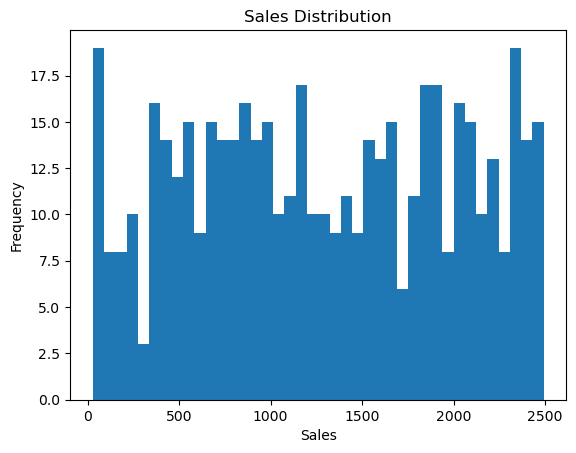

In [61]:
plt.hist(df["Sales"], bins=40)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Sales Distribution")
plt.show()

Profit Distribution

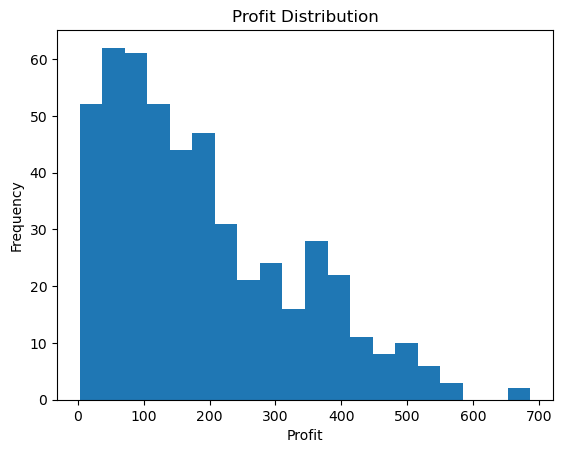

In [63]:
plt.hist(df["Profit"], bins=20)
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.title("Profit Distribution")
plt.show()

***Sales values are mostly concentrated in lower ranges or higher ranges.
Profit distribution shows whether transactions are mostly profitable.
Negative Profit values indicate loss-making transactions.***

***Category Analysis***

Sales BY Category

In [64]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print(category_sales)

Category
Technology         236184.41
Office Supplies    214342.48
Furniture          194260.80
Name: Sales, dtype: float64


Chart

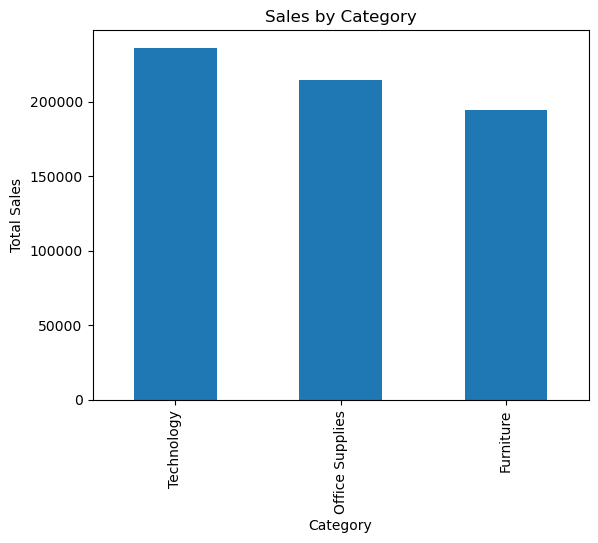

In [68]:
category_sales.plot(kind="bar")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.title("Sales by Category")
plt.show()

Profit BY Categoryu

In [69]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

print(category_profit)

Category
Technology         34490.99
Office Supplies    31444.62
Furniture          29089.69
Name: Profit, dtype: float64


Chart

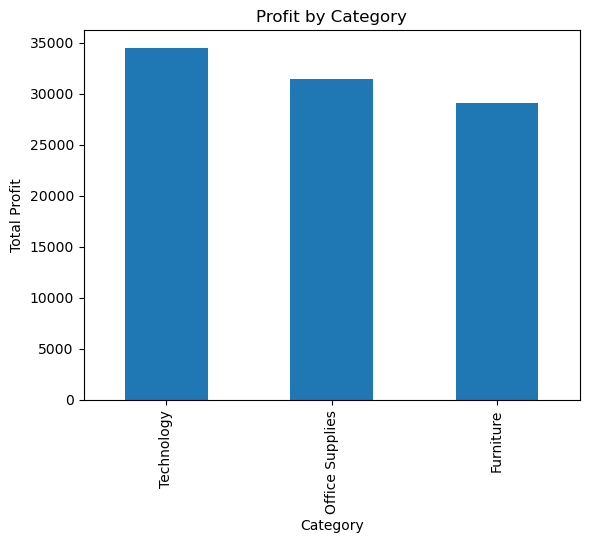

In [70]:
category_profit.plot(kind="bar")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.title("Profit by Category")
plt.show()

***Business Insight***

Which category generates the highest sales?
Which category generates the highest profit?
Is there any difference between Sales and Profit?

***Region Analysis***

Sales BY Region

In [71]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print(region_sales)

Region
West       251215.04
Central    190559.82
East       133131.10
South       69881.73
Name: Sales, dtype: float64


Chartt

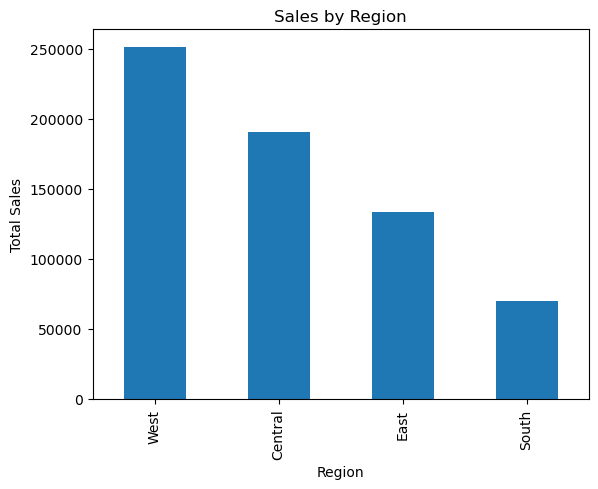

In [75]:
region_sales.plot(kind="bar")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.title("Sales by Region")
plt.show()

***Profit by Region***

In [73]:
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

print(region_profit)

Region
West       36226.58
Central    29406.26
East       19356.18
South      10036.28
Name: Profit, dtype: float64


Chart

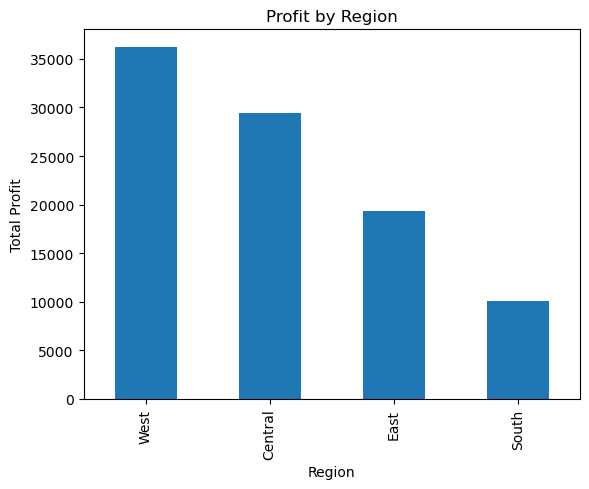

In [74]:
region_profit.plot(kind="bar")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.title("Profit by Region")
plt.show()

***Region Wise Sales And Profit***

In [76]:
region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()

print(region_analysis)

             Sales    Profit
Region                      
Central  190559.82  29406.26
East     133131.10  19356.18
South     69881.73  10036.28
West     251215.04  36226.58


***Monthly Sales Trend***

Monthly Sales

In [77]:
monthly_sales = df.groupby("Order_Month")["Sales"].sum()

print(monthly_sales)

Order_Month
April        58968.70
August       62687.66
December     52662.72
February     42680.60
January      46774.07
July         43217.56
June         71355.74
March        55624.01
May          52666.04
November     56894.71
October      59708.27
September    41547.61
Name: Sales, dtype: float64


chart

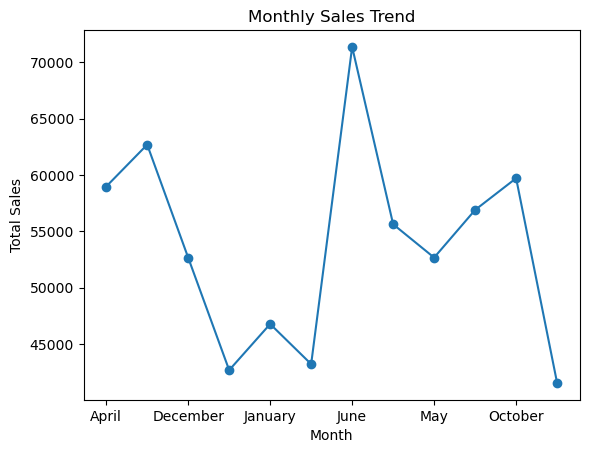

In [81]:
monthly_sales.plot(kind="line", marker="o")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.show()

Monthly Profit

In [82]:
monthly_profit = df.groupby("Order_Month")["Profit"].sum()
print(monthly_profit)

Order_Month
April        8962.45
August       8131.98
December     7329.87
February     7453.15
January      6663.97
July         6260.01
June         9919.88
March        7486.33
May          8721.94
November     8443.64
October      9310.54
September    6341.54
Name: Profit, dtype: float64


Chart

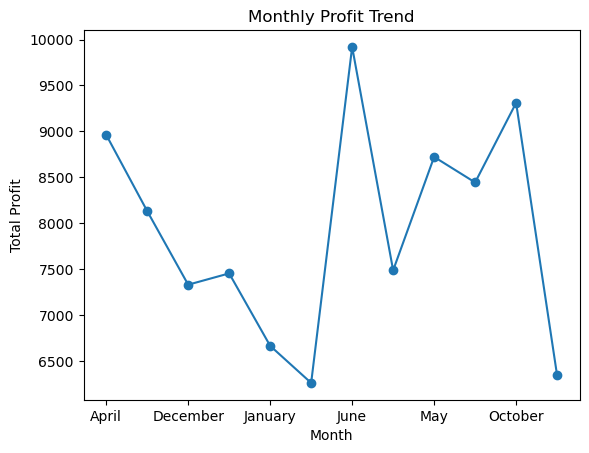

In [83]:
monthly_profit.plot(kind="line", marker="o")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.title("Monthly Profit Trend")
plt.show()

Monthly Sales And Profit

In [84]:
monthly_analysis = df.groupby("Order_Month")[["Sales", "Profit"]].sum()

print(monthly_analysis)

                Sales   Profit
Order_Month                   
April        58968.70  8962.45
August       62687.66  8131.98
December     52662.72  7329.87
February     42680.60  7453.15
January      46774.07  6663.97
July         43217.56  6260.01
June         71355.74  9919.88
March        55624.01  7486.33
May          52666.04  8721.94
November     56894.71  8443.64
October      59708.27  9310.54
September    41547.61  6341.54


***Top 10 Products***

Top 10 Product By Sales

In [85]:
top_products_sales = (
    df.groupby("Product_Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_sales)

Product_Name
Smartphone          31816.70
Conference Table    31250.97
Calculator          30512.75
Printer             30477.49
Color Copier        27925.14
Wood Bookcase       27789.22
Metal Bookcase      26651.85
Office Copier       26452.92
Desk Fan            26101.87
Office Phone        25952.66
Name: Sales, dtype: float64


CHart

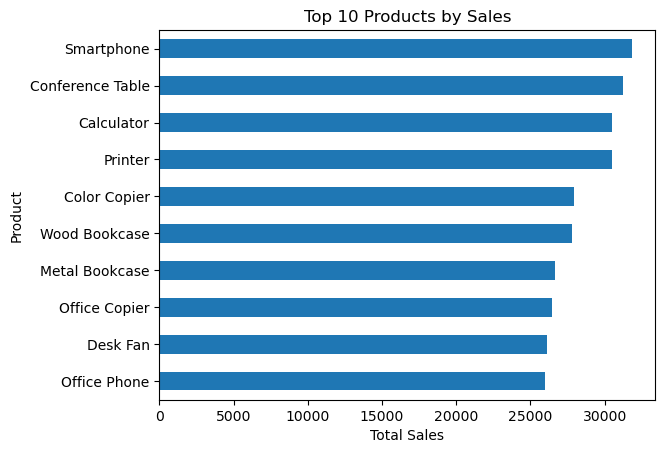

In [87]:
top_products_sales.plot(kind="barh")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.title("Top 10 Products by Sales")
plt.gca().invert_yaxis()
plt.show()

Top 10 product by Profit

In [88]:
top_products_profit = (
    df.groupby("Product_Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_profit)

Product_Name
Smartphone          5172.95
Wood Bookcase       4617.24
Calculator          4350.63
Desk Lamp           4341.46
Conference Table    4268.37
Office Copier       4134.77
Desk Fan            4082.23
Color Copier        4011.58
File Binder         3893.66
Printer             3869.42
Name: Profit, dtype: float64


Chart

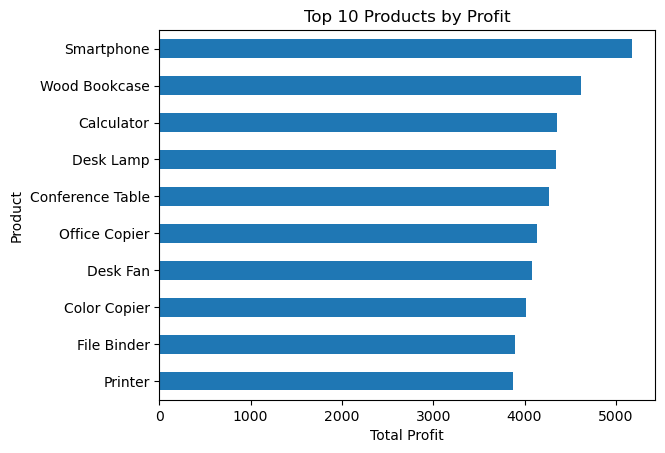

In [89]:
top_products_profit.plot(kind="barh")
plt.xlabel("Total Profit")
plt.ylabel("Product")
plt.title("Top 10 Products by Profit")
plt.gca().invert_yaxis()
plt.show()

bottom 10 Product By Profit

In [90]:
bottom_products_profit = (
    df.groupby("Product_Name")["Profit"]
    .sum()
    .sort_values()
    .head(10)
)

print(bottom_products_profit)

Product_Name
Wooden Table          792.12
Copy Paper           1084.13
USB Keyboard         1452.72
Shipping Labels      1461.90
Laptop Stand         1610.65
Art Pens             1697.18
Ergonomic Chair      1812.63
Office Furnishing    1817.22
File Storage         1901.88
Address Labels       2096.28
Name: Profit, dtype: float64


chart

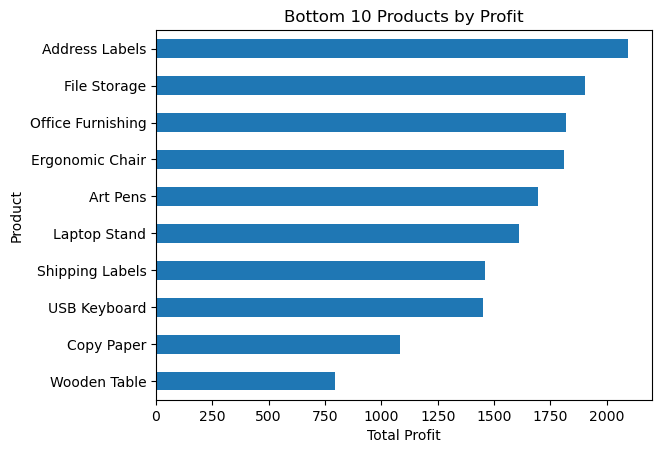

In [91]:
bottom_products_profit.plot(kind="barh")
plt.xlabel("Total Profit")
plt.ylabel("Product")
plt.title("Bottom 10 Products by Profit")
plt.show()

***Top 10 Customers***

Top 10 Customer By Sales

In [92]:
top_customers_sales = (
    df.groupby("Customer_Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers_sales)

Customer_Name
William Martin     56965.42
Robert Jackson     47638.32
Rahul Sharma       46682.68
Sarah Wilson       44922.81
Daniel Anderson    42974.76
Amit Patil         41483.29
Emily White        41252.60
Neha Joshi         39732.17
Michael Brown      39535.30
Emma Davis         39414.57
Name: Sales, dtype: float64


chart

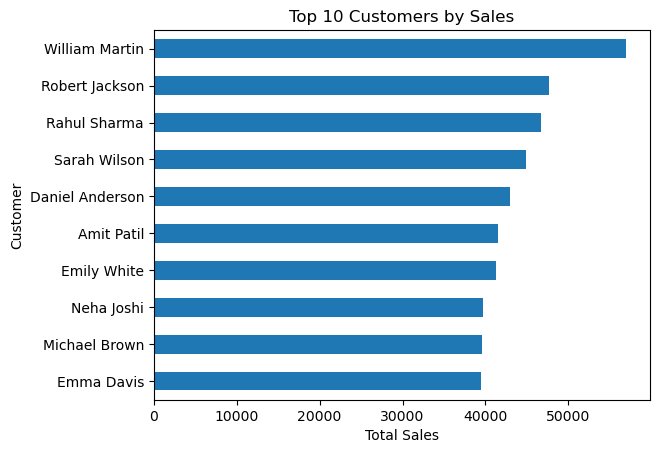

In [93]:
top_customers_sales.plot(kind="barh")
plt.xlabel("Total Sales")
plt.ylabel("Customer")
plt.title("Top 10 Customers by Sales")
plt.gca().invert_yaxis()
plt.show()

top 10 customer By Profit

In [94]:
top_customers_profit = (
    df.groupby("Customer_Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers_profit)

Customer_Name
William Martin     8416.41
Rahul Sharma       7260.57
Sarah Wilson       6747.94
Michael Brown      6731.23
Emily White        6637.75
Daniel Anderson    6460.72
Robert Jackson     6382.17
Amit Patil         6344.10
Neha Joshi         5653.28
Priya Shah         5540.90
Name: Profit, dtype: float64


chart

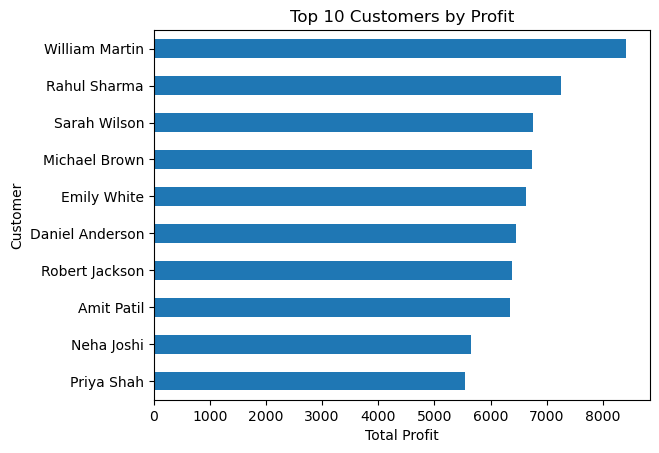

In [95]:
top_customers_profit.plot(kind="barh")
plt.xlabel("Total Profit")
plt.ylabel("Customer")
plt.title("Top 10 Customers by Profit")
plt.gca().invert_yaxis()
plt.show()

top 10 Customers by Sales AND Profit

In [96]:
customer_analysis = (
    df.groupby("Customer_Name")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
    .head(10)
)

print(customer_analysis)

                    Sales   Profit
Customer_Name                     
William Martin   56965.42  8416.41
Robert Jackson   47638.32  6382.17
Rahul Sharma     46682.68  7260.57
Sarah Wilson     44922.81  6747.94
Daniel Anderson  42974.76  6460.72
Amit Patil       41483.29  6344.10
Emily White      41252.60  6637.75
Neha Joshi       39732.17  5653.28
Michael Brown    39535.30  6731.23
Emma Davis       39414.57  5153.20


***Discount VS Profit***

In [98]:
discount_profit = df.groupby("Discount")["Profit"].mean()
print(discount_profit)

Discount
0.00    209.103614
0.05    207.473766
0.10    211.009219
0.15    211.510143
0.20    194.564821
0.25    151.193699
0.30    148.716234
Name: Profit, dtype: float64


scatter Plot

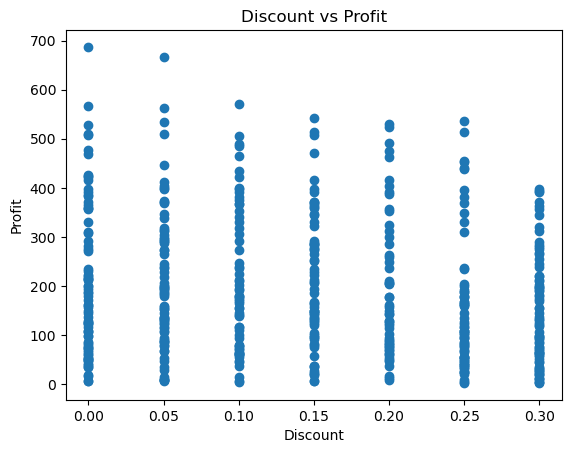

In [99]:
plt.scatter(df["Discount"], df["Profit"])
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.title("Discount vs Profit")
plt.show()

I analyzed the relationship between discount and profit using Python scatter plots and grouped analysis to understand how discounting impacts profitability.

***FINAL BUSINESS INSIGHTS***

Category Performace

In [102]:
category_analysis = df.groupby("Category")[["Sales", "Profit"]].sum()

print(category_analysis)

                     Sales    Profit
Category                            
Furniture        194260.80  29089.69
Office Supplies  214342.48  31444.62
Technology       236184.41  34490.99


Region Performace

In [104]:
region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()

print(region_analysis)

             Sales    Profit
Region                      
Central  190559.82  29406.26
East     133131.10  19356.18
South     69881.73  10036.28
West     251215.04  36226.58


Most Profitable Product

In [105]:
product_profit = (
    df.groupby("Product_Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(product_profit.head(10))

Product_Name
Smartphone          5172.95
Wood Bookcase       4617.24
Calculator          4350.63
Desk Lamp           4341.46
Conference Table    4268.37
Office Copier       4134.77
Desk Fan            4082.23
Color Copier        4011.58
File Binder         3893.66
Printer             3869.42
Name: Profit, dtype: float64


Loss Meking Product

In [107]:
loss_products = (
    df.groupby("Product_Name")["Profit"]
    .sum()
    .sort_values()
)

print(loss_products.head(10))

Product_Name
Wooden Table          792.12
Copy Paper           1084.13
USB Keyboard         1452.72
Shipping Labels      1461.90
Laptop Stand         1610.65
Art Pens             1697.18
Ergonomic Chair      1812.63
Office Furnishing    1817.22
File Storage         1901.88
Address Labels       2096.28
Name: Profit, dtype: float64


Overall Profit Margin

In [108]:
profit_margin = (df["Profit"].sum() / df["Sales"].sum()) * 100
print("Overall Profit Margin:", profit_margin, "%")

Overall Profit Margin: 14.737455673199968 %


***Final Python Business Insights***

In [ ]:
# Technology is the strongest category based on sales and profit.
# Top-performing regions can be identified based on total sales and profit.
# Top products contribute significantly to overall revenue and profit.
# Low-profit/loss-making products require further investigation.
# Higher discounts may negatively impact profitability.
# Monthly analysis helps identify high and low-performing periods.
# Customer analysis helps identify high-value customers.